# Supplementary analysis

In [1]:
include("main_utils.jl")
include("data_setup.jl")
include("suppl_utils.jl")

default_plot_setting()

Plots.GRBackend()

## Comparison of sample means v.s. estimated means 

In [2]:
include("suppl_utils.jl")
df_res = read_master_with_fit_summary();
df_res = filter_surveys(df_res);

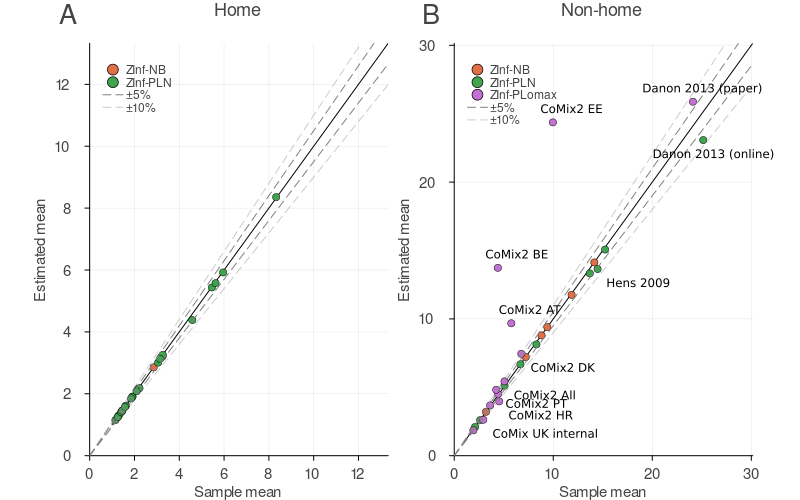

In [3]:
include("suppl_utils.jl")
pl = plot_validation_sample_vs_estimated(df_res)
savefig(pl, "../fig/validation_plot.png")
pl

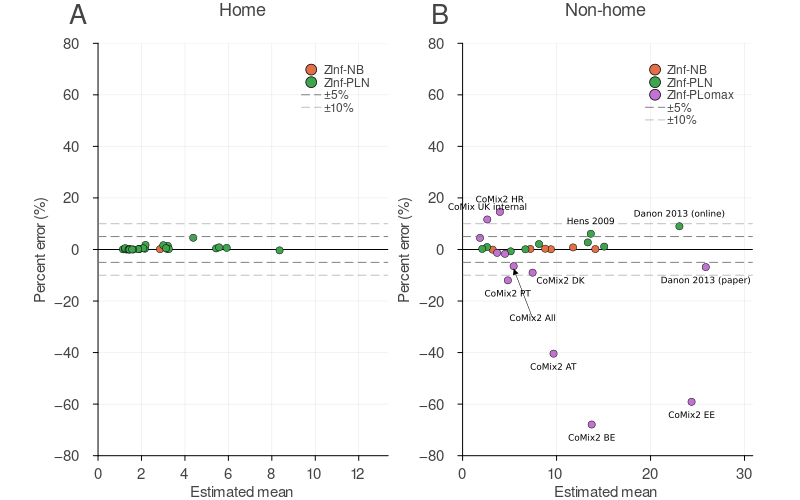

In [4]:
include("suppl_utils.jl")
pl = plot_validation_est_vs_pc_error(df_res)
savefig(pl, "../fig/validation_plot_pc_error.png")
pl

### Visualisation of fitting qualities for disaggregated CoMix2 surveys

In [5]:
keys_ = ["CoMix2_gr", "CoMix2_it", "CoMix2_pt",
    "CoMix2_hr", "CoMix2_ee", "CoMix2_at",
    "CoMix2_dk", "CoMix2_be", "CoMix2_pl",
];

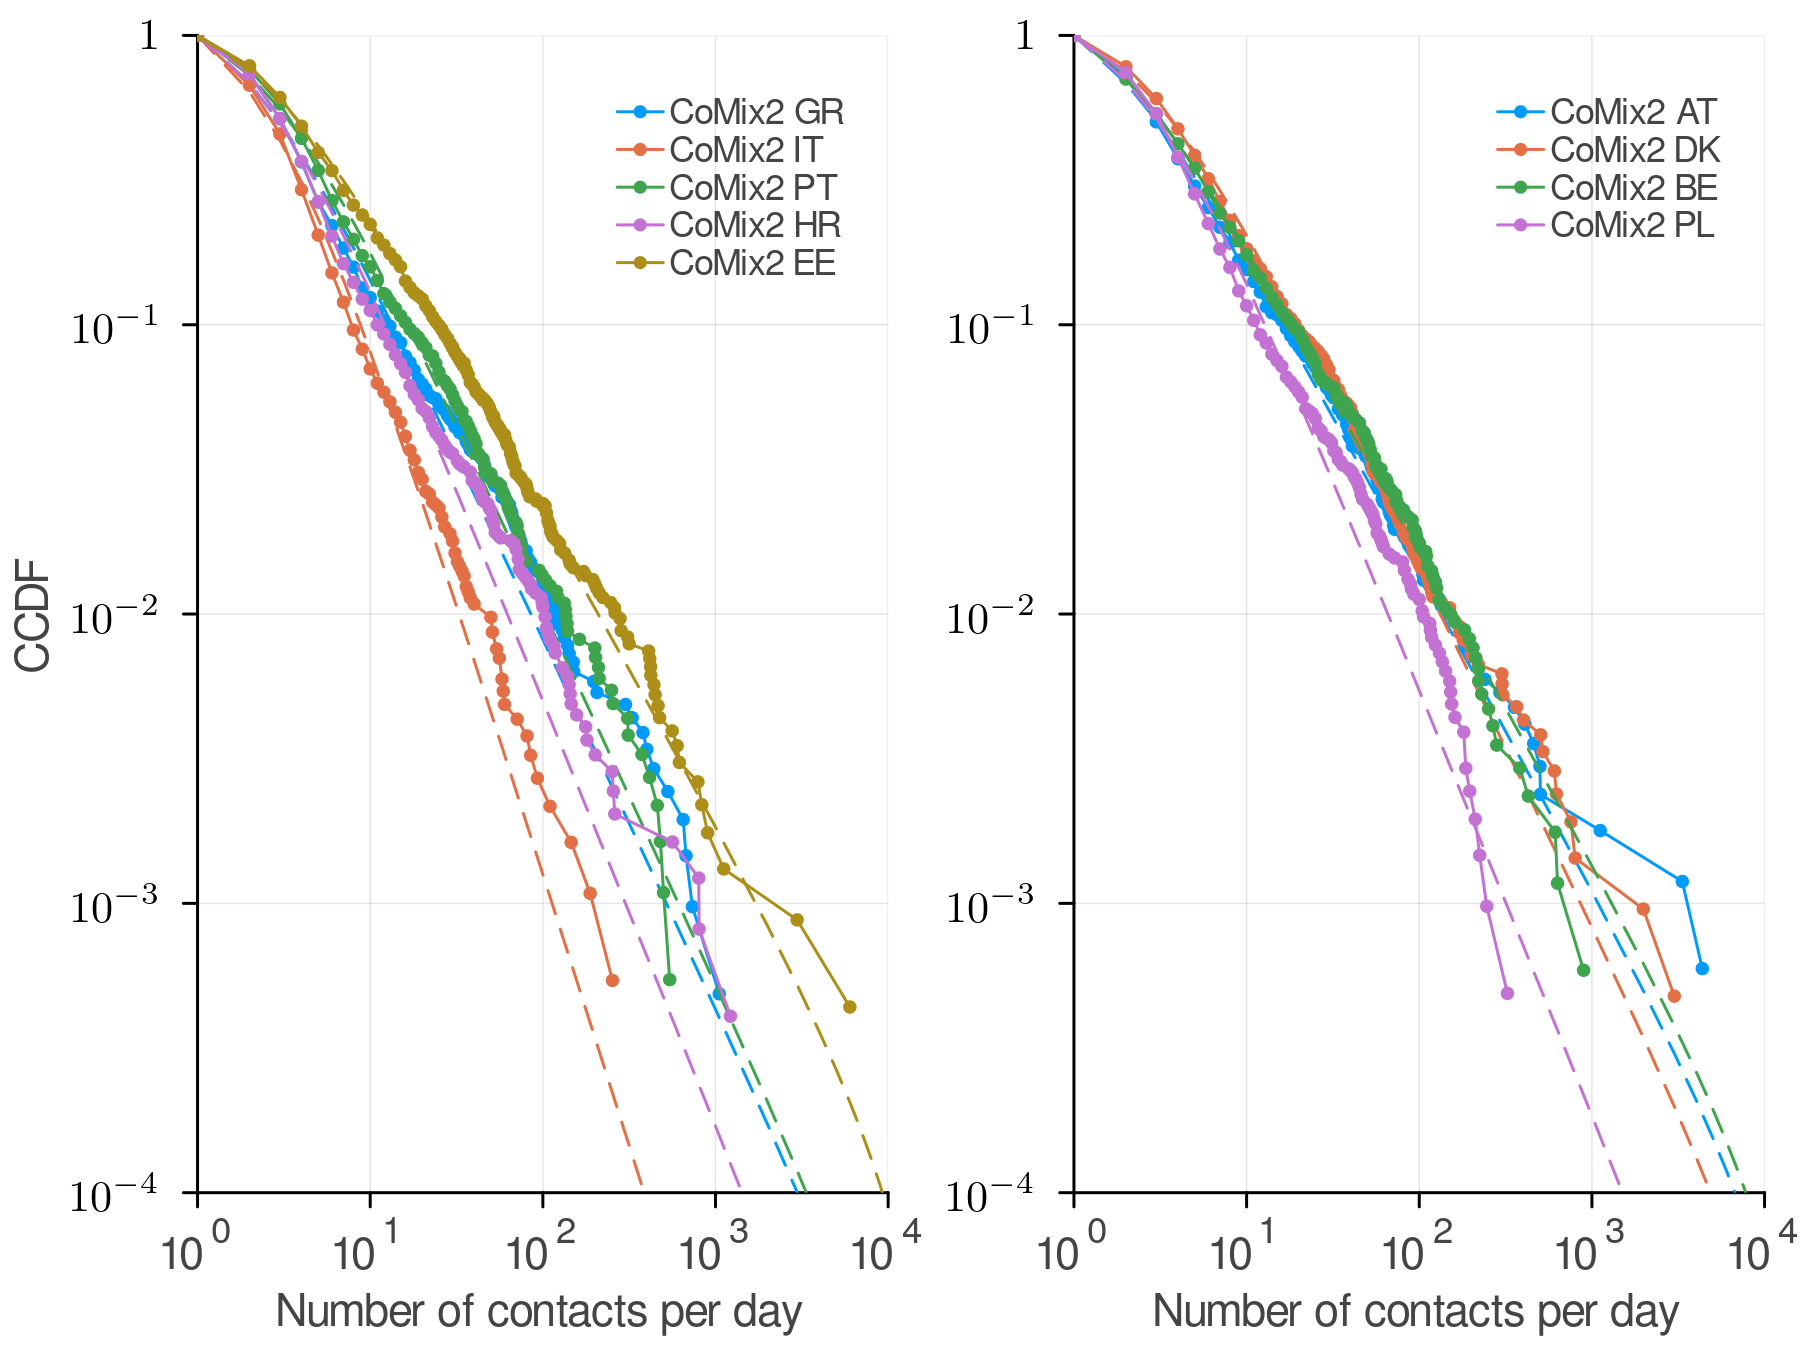

In [6]:
include("fit_utils.jl")
include("distributions/main.jl")
k = keys_[1]
pl1 = plot_multi_ccdf_poisson_lomax(keys_[1:5],
    xlabel="Number of contacts per day", ylabel="CCDF")
pl2 = plot_multi_ccdf_poisson_lomax(keys_[6:end],
    xlabel="Number of contacts per day")
pl = plot(pl1, pl2, dpi=300, )
savefig(pl, "../fig/fitted_poisson_lomax.png")
pl

## Validation of estimation methods: numerical v.s. hierarhical

In [7]:
include("turing_models.jl")
include("suppl_utils.jl")

plot_validation_PLomax (generic function with 1 method)

In [8]:
# Fetch true parameters
model_names = get_model_names()
chns_nhm = load("../dt_intermediate/Danon_2013_post_chns.jld2")["result"]["chns_non-home"]
dists_nhm = [get_ZeroInfDist(chns_nhm[m], m) for m in model_names]
μ_true = 2.1996539572904394
σ_true = 1.382422656974451
d_true_PLN = PoissonLogNormal(μ=μ_true, σ=σ_true)

chns_nhm = load("../dt_intermediate/CoMix2_chns.jld2")["result"]["chns_non-home"]
dists_nhm = [get_ZeroInfDist(chns_nhm[m], m) for m in model_names]
α_true = 1.2397377817920316
β_true = 1.7595826910422334
d_true_PLomax = PoissonLomax(α=α_true, θ=β_true);


In [9]:
df_res_PLN = validation_PLN(d_true_PLN, 100);
df_res_PLomax = validation_PLomax(d_true_PLomax, 100);
CSV.write("../dt_intermediate/validation_PLN.csv", df_res_PLN)
CSV.write("../dt_intermediate/validation_PLomax.csv", df_res_PLomax)

┌ Info: Found initial step size
└   ϵ = 0.05
┌ Info: Found initial step size
└   ϵ = 0.05
┌ Info: Found initial step size
└   ϵ = 0.05
┌ Info: Found initial step size
└   ϵ = 0.05
┌ Info: Found initial step size
└   ϵ = 0.05
┌ Info: Found initial step size
└   ϵ = 0.05
┌ Info: Found initial step size
└   ϵ = 0.2


┌ Info: Found initial step size
└   ϵ = 0.05
┌ Info: Found initial step size
└   ϵ = 0.05
┌ Info: Found initial step size
└   ϵ = 0.05
┌ Info: Found initial step size
└   ϵ = 0.2
┌ Info: Found initial step size
└   ϵ = 0.05


 75.830635 seconds (272.55 M allocations: 227.501 GiB, 39.92% gc time, 378.98% compilation time)
 75.829881 seconds (272.52 M allocations: 227.492 GiB, 39.92% gc time, 378.79% compilation time)
 75.829360 seconds (272.51 M allocations: 227.487 GiB, 39.92% gc time, 378.60% compilation time)
 75.831790 seconds (272.59 M allocations: 227.513 GiB, 39.92% gc time, 379.17% compilation time)
 76.202576 seconds (282.83 M allocations: 229.615 GiB, 39.91% gc time, 379.09% compilation time)
 76.265485 seconds (284.99 M allocations: 229.952 GiB, 39.90% gc time, 379.31% compilation time)
 76.722819 seconds (294.22 M allocations: 232.028 GiB, 39.85% gc time, 380.50% compilation time)
 76.747360 seconds (295.17 M allocations: 232.169 GiB, 39.83% gc time, 380.43% compilation time)
 77.438194 seconds (302.64 M allocations: 233.949 GiB, 39.65% gc time, 379.61% compilation time)
 78.117557 seconds (311.49 M allocations: 234.760 GiB, 39.35% gc time, 376.31% compilation time)
 78.270705 seconds (312.63 M a

┌ Info: Found initial step size
└   ϵ = 0.05
┌ Info: Found initial step size
└   ϵ = 0.05
┌ Info: Found initial step size
└   ϵ = 0.05
┌ Info: Found initial step size
└   ϵ = 0.05
┌ Info: Found initial step size
└   ϵ = 0.05
┌ Info: Found initial step size
└   ϵ = 0.05
┌ Info: Found initial step size
└   ϵ = 0.05
┌ Info: Found initial step size
└   ϵ = 0.05
┌ Info: Found initial step size
└   ϵ = 0.05
┌ Info: Found initial step size
└   ϵ = 0.05
┌ Info: Found initial step size
└   ϵ = 0.05
┌ Info: Found initial step size
└   ϵ = 0.05
┌ Info: Found initial step size
└   ϵ = 0.05
┌ Info: Found initial step size
└   ϵ = 0.05
┌ Info: Found initial step size
└   ϵ = 0.05
┌ Info: Found initial step size
└   ϵ = 0.05
┌ Info: Found initial step size
└   ϵ = 0.05
┌ Info: Found initial step size
└   ϵ = 0.05


 15.036548 seconds (167.12 M allocations: 11.912 GiB, 8.43% gc time, 369.89% compilation time)
 15.042595 seconds (167.26 M allocations: 11.921 GiB, 8.43% gc time, 369.74% compilation time)
 15.041192 seconds (167.25 M allocations: 11.922 GiB, 8.43% gc time, 369.77% compilation time)
 15.430295 seconds (171.68 M allocations: 13.170 GiB, 9.20% gc time, 360.45% compilation time)
 15.797454 seconds (175.73 M allocations: 14.727 GiB, 10.11% gc time, 352.07% compilation time)
 16.124309 seconds (178.97 M allocations: 16.221 GiB, 10.93% gc time, 344.94% compilation time)
 16.368353 seconds (181.47 M allocations: 17.456 GiB, 11.51% gc time, 339.79% compilation time)
 17.870526 seconds (195.24 M allocations: 25.871 GiB, 14.80% gc time, 311.23% compilation time)
 17.985951 seconds (195.19 M allocations: 27.782 GiB, 15.60% gc time, 297.97% compilation time)
 18.509122 seconds (200.51 M allocations: 29.251 GiB, 15.83% gc time, 300.49% compilation time)
 21.878610 seconds (224.00 M allocations: 49

┌ Info: Found initial step size
└   ϵ = 0.2


... (195 outputs left out)

┌ Info: Found initial step size
└   ϵ = 0.2


  3.302402 seconds (53.15 M allocations: 5.748 GiB, 14.48% gc time)


  1.602265 seconds (12.35 M allocations: 877.478 MiB, 3.40% gc time)


"../dt_intermediate/validation_PLomax.csv"

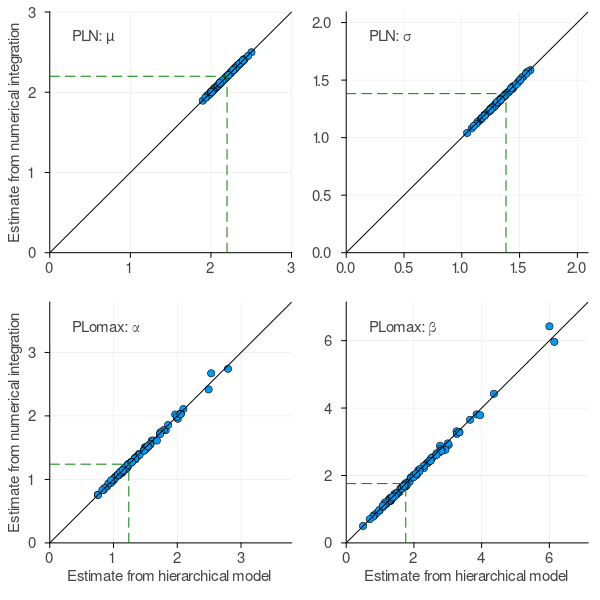

In [10]:
include("suppl_utils.jl")
df_res_PLN = CSV.read("../dt_intermediate/validation_PLN.csv", DataFrame)
df_res_PLomax = CSV.read("../dt_intermediate/validation_PLomax.csv", DataFrame)
pls1 = plot_validation_PLN(df_res_PLN, μ_true, σ_true)
pls2 = plot_validation_PLomax(df_res_PLomax, α_true, β_true)
pl = plot(pls1..., pls2..., size=(600, 600))
savefig(pl, "../fig/validation_num_vs_hierarchical.png")
pl